In [34]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

print(f"Running on PyMC v{pm.__version__}")

Running on PyMC v5.10.2


In [35]:
az.style.use("arviz-darkgrid")

In [36]:
y = np.array([28, 8, -3, 7, -1, 1, 18, 12])
sigma = np.array([15, 10, 16, 11, 9, 11, 10, 18])
J = len(y)

In [37]:
with pm.Model() as pooled:
    # Latent pooled effect size
    mu = pm.Normal("mu", 0, sigma=1e6)

    obs = pm.Normal("obs", mu, sigma=sigma, observed=y)

    trace_p = pm.sample(2000)
    
    idat = pm.sample_smc(random_seed=42)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 6 seconds.
Initializing SMC sampler...
Sampling 4 chains in 4 jobs


In [38]:
idat.sample_stats["log_marginal_likelihood"]

<xarray.DataArray 'log_marginal_likelihood' (chain: 4, draw: 8)>
array([[nan, nan, nan, nan, nan, nan, nan, -42.062086247458964],
       [nan, nan, nan, nan, nan, nan, nan, -42.32281860824801],
       [nan, nan, nan, nan, nan, nan, nan, -41.94706525190025],
       [nan, nan, nan, nan, nan, nan, nan, -41.839984383938315]],
      dtype=object)
Coordinates:
  * chain    (chain) int64 0 1 2 3
  * draw     (draw) int64 0 1 2 3 4 5 6 7

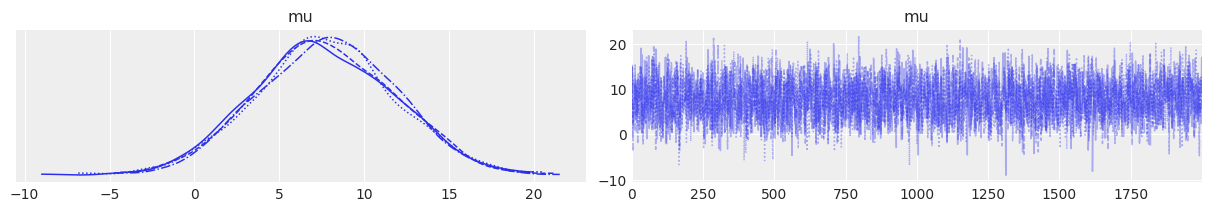

In [39]:
az.plot_trace(trace_p);

In [40]:
with pooled:
    pm.compute_log_likelihood(trace_p)

In [41]:
pooled_loo = az.loo(trace_p)

pooled_loo

Computed from 8000 posterior samples and 8 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -30.58     1.11
p_loo        0.69        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.5]   (good)        8  100.0%
 (0.5, 0.7]   (ok)          0    0.0%
   (0.7, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%

In [42]:
trace_p

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data

In [43]:
from scipy.special import betaln
from scipy.stats import beta

In [44]:
def beta_binom(prior, y):
    """
    Compute the marginal likelihood, analytically, for a beta-binomial model.

    prior : tuple
        tuple of alpha and beta parameter for the prior (beta distribution)
    y : array
        array with "1" and "0" corresponding to the success and fails respectively
    """
    alpha, beta = prior
    h = np.sum(y)
    n = len(y)
    p_y = np.exp(betaln(alpha + h, beta + n - h) - betaln(alpha, beta))
    return p_y

In [45]:
y = np.repeat([1, 0], [50, 50])  # 50 "heads" and 50 "tails"
priors = ((1, 1), (30, 30), (40,40))

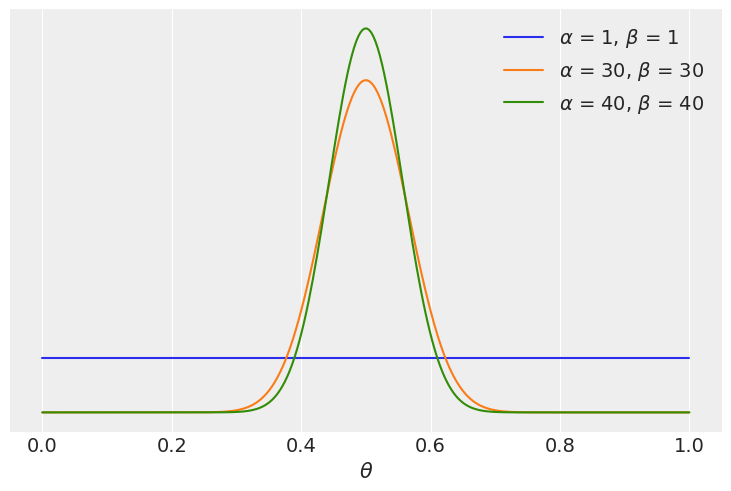

In [46]:
for a, b in priors:
    distri = beta(a, b)
    x = np.linspace(0, 1, 300)
    x_pdf = distri.pdf(x)
    plt.plot(x, x_pdf, label=rf"$\alpha$ = {a:d}, $\beta$ = {b:d}")
    plt.yticks([])
    plt.xlabel("$\\theta$")
    plt.legend()

In [49]:
models = []
idatas = []
for alpha, beta in priors:
    with pm.Model() as model:
        a = pm.Beta("a", alpha, beta)
        yl = pm.Bernoulli("yl", a, observed=y)
        idata = pm.sample_smc(draws=5000, random_seed=42, cores=8, parallel = False)
        models.append(model)
        idatas.append(idata)

/tmp/ipykernel_98234/4137997492.py:7: FutureWarning: The argument parallel is deprecated, use the argument cores instead.
  idata = pm.sample_smc(draws=5000, random_seed=42, cores=8, parallel = False)
Initializing SMC sampler...
Sampling 2 chains in 1 job


We recommend running at least 4 chains for robust computation of convergence diagnostics
/tmp/ipykernel_98234/4137997492.py:7: FutureWarning: The argument parallel is deprecated, use the argument cores instead.
  idata = pm.sample_smc(draws=5000, random_seed=42, cores=8, parallel = False)
Initializing SMC sampler...
Sampling 2 chains in 1 job


/home/lorenz/.local/lib/python3.10/site-packages/arviz/data/base.py:221: UserWarning: More chains (2) than draws (1). Passed array should have shape (chains, draws, *shape)
  warnings.warn(
We recommend running at least 4 chains for robust computation of convergence diagnostics
/tmp/ipykernel_98234/4137997492.py:7: FutureWarning: The argument parallel is deprecated, use the argument cores instead.
  idata = pm.sample_smc(draws=5000, random_seed=42, cores=8, parallel = False)
Initializing SMC sampler...
Sampling 2 chains in 1 job


/home/lorenz/.local/lib/python3.10/site-packages/arviz/data/base.py:221: UserWarning: More chains (2) than draws (1). Passed array should have shape (chains, draws, *shape)
  warnings.warn(
We recommend running at least 4 chains for robust computation of convergence diagnostics


In [50]:
BF_smc = np.exp(
    idatas[1].sample_stats["log_marginal_likelihood"].mean()
    - idatas[0].sample_stats["log_marginal_likelihood"].mean()
)
np.round(BF_smc).item()

5.0

In [16]:
idatas[0].sample_stats

<xarray.Dataset>
Dimensions:                  (chain: 8, draw: 3)
Coordinates:
  * chain                    (chain) int64 0 1 2 3 4 5 6 7
  * draw                     (draw) int64 0 1 2
Data variables:
    log_marginal_likelihood  (chain, draw) object nan nan -71.42 ... nan -71.41
    beta                     (chain, draw) object 0.0977783203125 ... 1
    accept_rate              (chain, draw) object 0.9845 0.9983 ... 0.9921
Attributes:
    created_at:                 2024-05-07T10:27:28.983656
    arviz_version:              0.16.1
    inference_library:          pymc
    inference_library_version:  5.10.2
    _n_draws:                   5000
    threshold:                  0.5
    _n_tune:                    4
    correlation_threshold:      0.01
    _t_sampling:                8.460415363311768

In [17]:
idatas[0].sample_stats["log_marginal_likelihood"]

<xarray.DataArray 'log_marginal_likelihood' (chain: 8, draw: 3)>
array([[nan, nan, -71.41830621404992],
       [nan, nan, -71.41602284727261],
       [nan, nan, -71.3843560997449],
       [nan, nan, -71.41550351276167],
       [nan, nan, -71.3765781790374],
       [nan, nan, -71.41258245214473],
       [nan, nan, -71.36891300121896],
       [nan, nan, -71.40547925887218]], dtype=object)
Coordinates:
  * chain    (chain) int64 0 1 2 3 4 5 6 7
  * draw     (draw) int64 0 1 2

In [18]:
idatas[1].sample_stats["log_marginal_likelihood"]


<xarray.DataArray 'log_marginal_likelihood' (chain: 8, draw: 1)>
array([[-69.81898772127312],
       [-69.80101068897498],
       [-69.81036486155139],
       [-69.80840848615607],
       [-69.79560215640323],
       [-69.82063317558448],
       [-69.80915835161485],
       [-69.80235310583218]], dtype=object)
Coordinates:
  * chain    (chain) int64 0 1 2 3 4 5 6 7
  * draw     (draw) int64 0